# AgriLens: reproducible Egyptian PoC
**Theme: Precision Agriculture & Crop Intelligence**

This notebook reads the committed 615-row Egyptian sample, reruns the existing v1.2 forecast-residual method, applies the committed retrospective scene-QA overlay, creates charts and spatial exports, and inspects real EMIT spectra. No credentials or network requests are needed after installing requirements.txt.

**Current expected result: 16 raw flags, 5 scene-QA holds, 11 review candidates.** The earlier 15 / 5 / 10 result belongs to an older feature configuration. A candidate is an observation for human review, not a confirmed dust/drought diagnosis. The dashboard uses a separate median-deviation method (36 / 13 / 23).

Run all cells in a fresh Python 3 kernel. Outputs go to output/notebook_run, leaving the frozen example results intact.

In [1]:
# Locate the extracted project from the root or a notebook subfolder.
from pathlib import Path
import sys, json, hashlib, subprocess
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents]
            if (p / "scripts/ndvi_anomaly_detection.py").is_file())
INPUT = ROOT / "validation/data/agrilens_real_field_date_QA_gated_615.csv"
OUT = ROOT / "output/notebook_run"
OUT.mkdir(parents=True, exist_ok=True)
print("Python:", sys.version.split()[0])
print("Input:", INPUT.relative_to(ROOT))

Python: 3.12.14
Input: validation/data/agrilens_real_field_date_QA_gated_615.csv


## 1. Verify the example input
Each row is one field on one observation date. Field IDs define disjoint geographic training, validation and test groups. These 615 rows are not 615 independent farms.

In [2]:
data = pd.read_csv(INPUT, dtype={"field_id": "string"})
assert len(data) == 615 and data.field_id.nunique() == 20
assert data.groupby("field_id").field_split.nunique().max() == 1
splits = data.groupby("field_split").field_id.nunique().to_dict()
assert splits == {"train": 9, "validation": 6, "test": 5}, splits
input_hash = hashlib.sha256(INPUT.read_bytes()).hexdigest()
assert input_hash == "5919ffbdc2b33b6f3b3fd9c31f534889d80b2aa80cce4ceed1f04192a21c30c6"
print("Rows:", len(data), "Fields:", data.field_id.nunique(), "Split:", splits)
display(data.head())

Rows: 615 Fields: 20 Split: {'test': 5, 'train': 9, 'validation': 6}


,field_id,date,pixel_count,ndvi_mean,ndmi_mean,evi_mean,aot_s2_mean,coverage_ratio_vs_p90,low_coverage,quarantined_polygon,...,risk_interpretation,v2_ndvi_slope3_total,v2_ndvi_dev_from_prev5_median,v2_cusum_neg,qa_ndvi_slope3_total,qa_ndvi_dev_from_prev5_median,qa_cusum_neg_reset,qa_temporal_pair_ok,qa_window3_ok,qa_window_prev5_ok
0,1487525,2025-03-16,43,0.479524,0.121845,0.362718,0.216465,1.000000,False,False,...,contemporaneous screening indicators; no attri...,NaN,NaN,0.000000,NaN,NaN,NaN,False,False,False
1,1487525,2025-03-26,39,0.405328,0.099805,0.325163,0.276000,0.906977,False,False,...,contemporaneous screening indicators; no attri...,NaN,NaN,-0.064195,NaN,NaN,-0.064195,True,False,False
2,1487525,2025-03-31,43,0.440409,0.118276,0.333541,0.402000,1.000000,False,False,...,contemporaneous screening indicators; no attri...,-0.039115,NaN,-0.019115,-0.039115,NaN,-0.019115,True,True,False
3,1487525,2025-04-05,43,0.421281,0.107740,0.332094,0.306000,1.000000,False,False,...,contemporaneous screening indicators; no attri...,0.015952,-0.019128,-0.028243,0.015952,-0.019128,-0.028243,True,True,True
4,1487525,2025-04-15,43,0.385965,0.089624,0.316411,0.316698,1.000000,False,False,...,contemporaneous screening indicators; no attri...,-0.054444,-0.044879,-0.053558,-0.054444,-0.044879,-0.053558,True,True,True


## 2. Run the existing model
The module builds historical features, selects Ridge strength using validation fields, and calibrates the negative-residual threshold using training-field out-of-fold predictions. The held-out test fields remain outside fitting and calibration. The scene overlay is retrospective and does not erase raw statistical flags.

In [3]:
command = [sys.executable, str(ROOT / "scripts/ndvi_anomaly_detection.py"),
           "--input", str(INPUT), "--repo-root", str(ROOT), "--output-dir", str(OUT),
           "--scene-qa", str(ROOT / "validation/results/date_scene_QA.csv"),
           "--coordinate-reference", str(ROOT / "validation/results/field_geography.csv")]
run = subprocess.run(command, cwd=ROOT, text=True, capture_output=True)
if run.returncode:
    raise RuntimeError(run.stdout + run.stderr)
print(run.stdout[-3500:])


AgriLens NDVI modeling completed.
Input:   /workspace/scratch/c0403863d728/work/AgriLens_GitHub_Ready_FINAL/validation/data/agrilens_real_field_date_QA_gated_615.csv
Outputs: /workspace/scratch/c0403863d728/work/AgriLens_GitHub_Ready_FINAL/output/notebook_run
Selected forecast baseline: ridge
Training-calibrated anomaly threshold: -0.09187
Held-out test anomaly flags: 3
Scene QA held flags (all splits): 5
Interpretation: anomaly screening only; dust/drought cause remains undetermined.



## 3. Check the results automatically
Counts below come from the newly generated files. Five flagged observations fall on the suspected 17 May 2025 scene. They remain visible as quality holds. Their cause has not been proven by ground observations.

,Stage,Observations
0,Raw statistical flags,16
1,Scene-QA holds,5
2,Review candidates,11


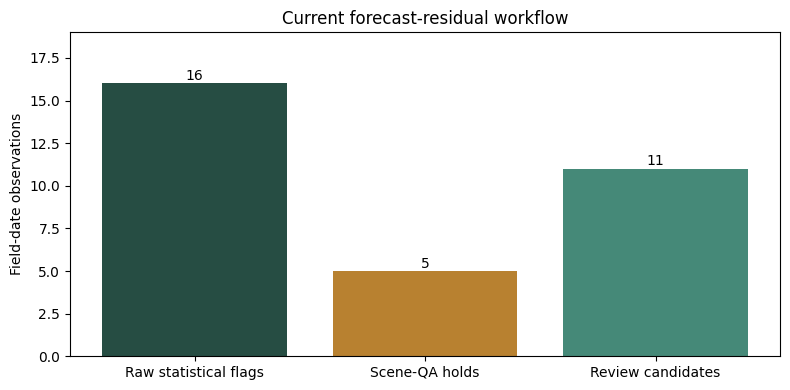

In [4]:
manifest = json.loads((OUT / "model_run_manifest.json").read_text())
raw = pd.read_csv(OUT / "all_split_anomaly_flags.csv")
held = pd.read_csv(OUT / "scene_qa_held_alerts.csv")
queue = pd.read_csv(OUT / "quality_screened_inspection_queue.csv")
counts = {"Raw statistical flags": len(raw), "Scene-QA holds": len(held), "Review candidates": len(queue)}
assert list(counts.values()) == [16, 5, 11], counts
assert len(raw) == len(held) + len(queue)
assert manifest["input_sha256"] == input_hash
assert manifest["scene_quality_overlay"]["suspect_dates"] == ["2025-05-17"]
for filename, expected in [("agrilens_spatial_alerts.geojson", 16), ("agrilens_screened_spatial_alerts.geojson", 11)]:
    assert len(json.loads((OUT / filename).read_text())["features"]) == expected
assert len(pd.read_csv(OUT / "field_date_ndvi_anomaly_results.csv")) == 595
display(pd.DataFrame(counts.items(), columns=["Stage", "Observations"]))
fig, ax = plt.subplots(figsize=(8, 4))
ax.bar(counts.keys(), counts.values(), color=["#264d43", "#b88130", "#458978"])
for i, v in enumerate(counts.values()): ax.text(i, v + .2, str(v), ha="center")
ax.set(ylabel="Field-date observations", title="Current forecast-residual workflow", ylim=(0, 19))
fig.tight_layout()
fig.savefig(OUT / "screening_summary.png", dpi=160)
plt.show()

## 4. Compare the held-out forecast with persistence
MAE and RMSE measure NDVI forecast error, not crop-damage classification accuracy. The selected Ridge model has lower RMSE, while persistence has lower MAE. Both results must remain visible.

,split,model,n_pairs,n_fields,mae,rmse,bias_observed_minus_predicted
6,test_holdout,Persistence,152,5,0.029575,0.043602,-0.001579
7,test_holdout,Ridge(alpha=1.0),152,5,0.031036,0.040376,-0.011370
8,test_holdout,Selected(ridge),152,5,0.031036,0.040376,-0.011370


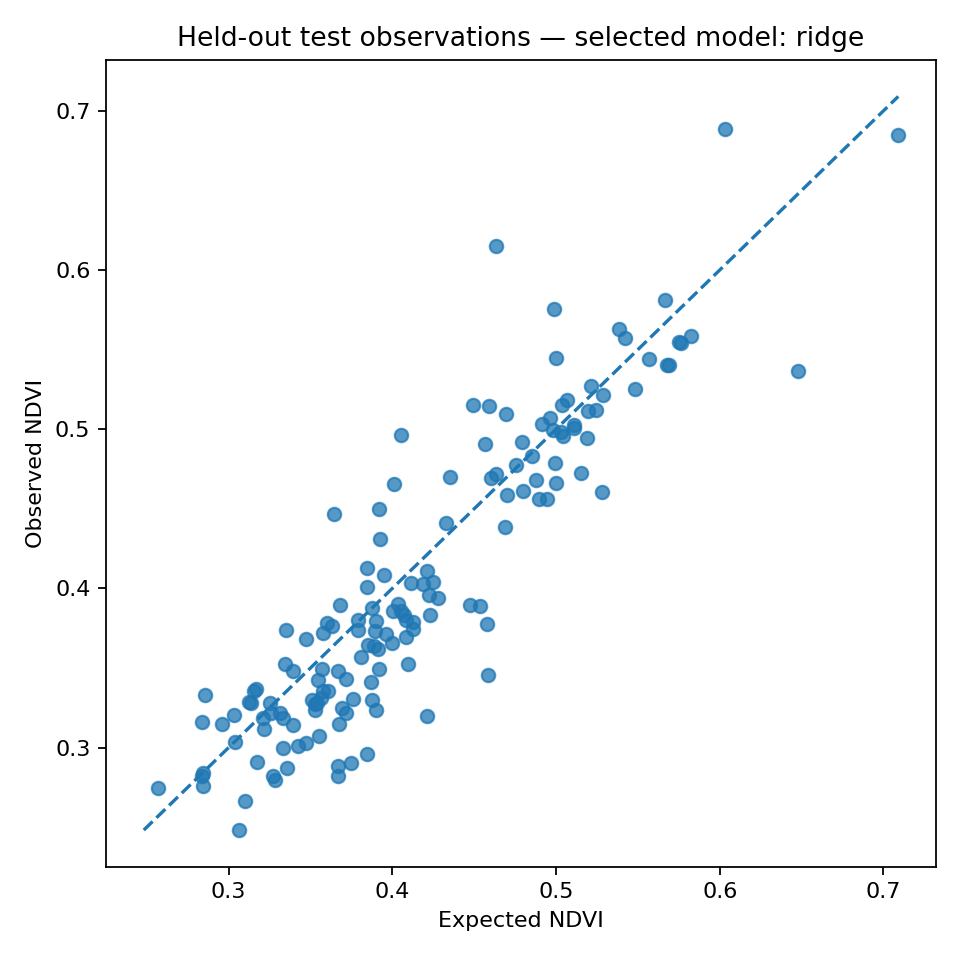

In [5]:
metrics = pd.read_csv(OUT / "forecast_metrics.csv")
test = metrics[metrics["split"] == "test_holdout"]
assert set(test.n_pairs) == {152}
display(test.round(6))
from IPython.display import Image
display(Image(filename=str(OUT / "figures/test_observed_vs_expected.png")))

## 5. Inspect real hyperspectral observations
NASA EMIT covers this study area on 15 June 2025. The retained sample contains 14 fields and 232 complete wavelengths. The paired Sentinel-2 observation is one day later. EMIT is an exploratory spectral component, not an input to the temporal forecast above. Six fields lack usable spectra, creating selection bias. No Satellite 813 observations are claimed.

field_split
test          5
train         3
validation    6
Name: Usable EMIT fields, dtype: int64

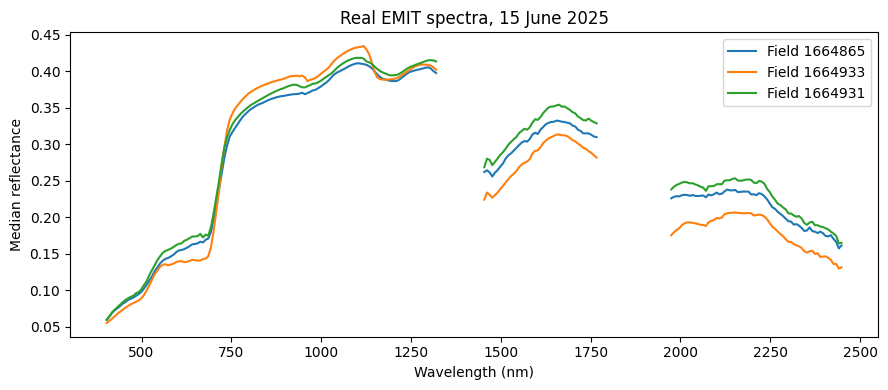

In [6]:
fields = pd.read_csv(ROOT / "03_EMIT_hyperspectral/EMIT_S2_usable_14_fields.csv")
spectra = pd.read_csv(ROOT / "03_EMIT_hyperspectral/EMIT_complete_spectra_3248.csv")
assert fields.field_id.nunique() == 14
assert spectra.shape[0] == 3248 and spectra.wavelength_nm.nunique() == 232
assert spectra.reflectance_median.notna().all()
assert not spectra.duplicated(["field_id", "wavelength_nm"]).any()
assert (fields.s2_minus_emit_days == 1).all()
display(fields.groupby("field_split").size().rename("Usable EMIT fields"))
fig, ax = plt.subplots(figsize=(9, 4))
for row in fields.nlargest(3, "emit_valid_pixel_count").itertuples():
    d = spectra[spectra.field_id == row.field_id].sort_values("wavelength_nm")
    x = d.wavelength_nm.to_numpy(dtype=float)
    y = d.reflectance_median.to_numpy(dtype=float)
    for position in np.where(np.diff(x) > 20)[0][::-1]:
        x = np.insert(x, position + 1, np.nan)
        y = np.insert(y, position + 1, np.nan)
    ax.plot(x, y, label=f"Field {row.field_id}")
ax.set(xlabel="Wavelength (nm)", ylabel="Median reflectance", title="Real EMIT spectra, 15 June 2025")
ax.legend(); fig.tight_layout()
fig.savefig(OUT / "emit_spectra.png", dpi=160)
plt.show()

## 6. Interpretation and handoff
An agronomist can review the map and field history, inspect imagery, and request field evidence before changing irrigation. This PoC does not establish crop damage, water savings, yield improvements or generalisation to Jordan.

Open docs/index.html for the interactive demonstration. Its separate validation screen has 36 raw deviations, 13 scene holds and 23 remaining observations (14 positive, 9 negative). Never describe those 23 observations as the 11 candidates produced here.

See DATA_SOURCES_AND_ATTRIBUTION.md for sources and licence details, and SUBMISSION_CHECKLIST.md for the remaining platform actions.

In [7]:
print("PASS: sample, model outputs, 16/5/11 counts, GeoJSON and EMIT checks completed.")
print("Generated files:")
for path in sorted(OUT.glob("*")):
    print(path.relative_to(ROOT).as_posix())

PASS: sample, model outputs, 16/5/11 counts, GeoJSON and EMIT checks completed.
Generated files:
output/notebook_run/MODELING_REPORT.md
output/notebook_run/agrilens_screened_spatial_alerts.geojson
output/notebook_run/agrilens_spatial_alerts.geojson
output/notebook_run/all_split_anomaly_flags.csv
output/notebook_run/data_audit.json
output/notebook_run/emit_spectra.png
output/notebook_run/field_date_ndvi_anomaly_results.csv
output/notebook_run/field_summary.csv
output/notebook_run/figures
output/notebook_run/forecast_metrics.csv
output/notebook_run/heldout_test_alerts.csv
output/notebook_run/model_run_manifest.json
output/notebook_run/quality_screened_inspection_queue.csv
output/notebook_run/scene_qa_held_alerts.csv
output/notebook_run/screening_summary.png
output/notebook_run/threshold_calibration_residuals.csv
